# Map flux

 ### 1) Read L(nu;z).
 
 ### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).
 
 ### 3) Build sky map (x,y) in mas units.
 
 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 
 
 ### 5) Convert luminosity to flux and mirror in x.
 
 ### 6) Convolute with Gaussian elliptical beam.
 
 ### 7) Plotting.

### Import modules

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap

### User parameters

In [16]:
incl = 30.0 * np.pi / 180.0
Nx = 512
nu_target_GHz = 43

### Define some constants

In [3]:
h = 6.6260755e-27
eV = 1.602176e-12
kpc = 3.0856e21
distance = 16.4e3
convert = 206265.e3/(distance*kpc) # imagen a tamano angular (mas)
flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

In [4]:
def read_SEDsyn_cuts( filename='SEDsyn_cuts_ord.dat'):
    Ns = 512 # TODO: Leer de archivo
    nIn = 150 # TODO: Leer de archivo
    fname = filename
    #fname format: Esy, Lsy*Esy, Labssy, l
    data = np.loadtxt(fname, usecols=(0,2))
    Esy = np.zeros((nIn))
    Esy_test = np.zeros((nIn))
    Lsy = np.zeros((nIn,Ns))
    j=0
    for l in range(0,Ns): #do l = 1, Ns 
      j = l*nIn
      for i in range(0,nIn): #do i = 1, nIn
        Esy[i] = data[i,0]
        Lsy[i,l] = data[j+i,1]/Esy[i]
        if l == 0:
          Esy_test[i] = Esy[i]
        if Esy[i] != Esy_test[i]:
            print("ERROR")
            exit()

    return Esy, Lsy

In [5]:
def get_Lsyn_z( Esy, Lsy, nu_target):
    E_nu_target = h * nu_target * 1.e9 / eV
    # Step through energies:
    log_Eint = np.log10(Esy[1]/Esy[0])
    i_nu_target = int(np.log10( E_nu_target/Esy[0]) /log_Eint)
    return Lsy[i_nu_target, :]

In [6]:
def get_z_rz( filename='quant_FF.dat'):
    fname = filename
    data = np.loadtxt(fname, usecols=(0,2))
    return data[:,0], data[:,1]

### 1) Read L(nu;z).

In [7]:
Esy, Lsy = read_SEDsyn_cuts()

### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).

In [8]:
L_z = get_Lsyn_z( Esy, Lsy, nu_target_GHz)

 ### 3) Build sky map (x,y) in mas units.

In [9]:
z, r_z = get_z_rz()

In [10]:
y = z * np.sin( incl) * convert

In [11]:
x = np.linspace( 0, r_z[-1], Nx) * convert
dx = x[1] - x[0]

 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 

In [12]:
r_z_proj = r_z * convert
L_map = np.ones(( len( x), len( y))) * 0
for j in range( len( y)):
    for i in range( len( x)):
        if x[ i] < r_z_proj[ j]:
            L_map[i,j] = 2.0 * L_z[ j] * np.sqrt( r_z_proj[ j]**2.0 - x[ i]**2.0) / (np.pi * r_z_proj[ j]**2.0)
            L_map[i,j] = L_map[i,j] * dx
    # Correction factor for better conservation of luminosity
    temp = np.sum( L_map[:,j])
    L_map[:,j] = L_map[:,j] * 0.5*L_z[j] / temp

 ### 5) Convert luminosity to flux and mirror in x.

In [13]:
F_map = np.ones(( 2*len(x), len(y)))
x_map = np.ones(( 2*len(x)))
for i in range( len(L_map[:,0])):
    x_map[i+Nx] = x[i]
    x_map[Nx-i-1] = -x[i]
    for j in range( len(L_map[0,:])):
        F_map[i+Nx,j] = L_map[i,j]*flux
        F_map[Nx-i-1,j] = L_map[i,j]*flux

###  6) Convolute with Gaussian elliptical beam.

### 7) Plotting

In [14]:
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 16,
        "font.size": 16,
        "axes.linewidth":1,
        "axes.titlesize":20,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 10,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
}
matplotlib.rcParams.update(nice_fonts)

#### Flux map:

/usr/lib/python3/dist-packages/ipykernel_launcher.py:6: RuntimeWarning: divide by zero encountered in log10
  


<Figure size 432x288 with 0 Axes>

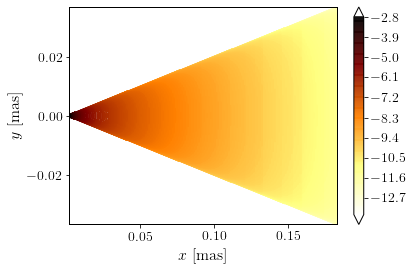

In [15]:
plt.clf()
fig, ax = plt.subplots()
ax.set_xlabel(r"$x$ [mas]")
ax.set_ylabel(r"$y$ [mas]")
cmap  = plt.cm.afmhot_r
CS = ax.contour( y, x_map, np.log10(F_map), cmap=cmap, levels=256, extend="both")
fig.colorbar( CS)